# Real Estate House Sale Price Prediction Using Machine Learning

**YEEAP Group Project Implementation | Group 23 | Google Colab**  
**Problem type:** Supervised regression  
**Target:** `SalePrice`  
**Dataset:** Uploaded Ames Housing dataset (`ames-housing.csv`)

This notebook follows all eight tasks in the Group Project Implementation Assignment. It is written for beginners: each section explains what the code does and why it is needed.

## Before running in Google Colab

1. Upload `Real_Estate_House_Sale_Price_Prediction_Colab.ipynb` to Google Colab.
2. Upload `ames-housing.csv` to the Colab session when the data-loading cell asks for it, or place the CSV in `/content/` with that exact filename.
3. Use **Runtime → Run all**. Model training may take a few minutes because the dataset contains categorical as well as numeric features.
4. At the end, download the generated `ames_housing_model.joblib` and files in `project_outputs/` if you need them outside Colab.

> **Currency and scope note:** The supplied dataset describes historical home sales in Ames, Iowa. Dataset documentation labels `SalePrice` in dollars (USD), not Ethiopian birr. This prototype is an educational estimate for the Ames dataset, not a local Ethiopian property valuation or a certified appraisal.

## Group information

The Module 4 proposal lists six original members and assigns technical roles using generic Member 1–5 labels. Addisu Melkie Tafere is included in the updated Module 6 group information supplied for this submission, with a focus on GitHub repository and deployment documentation. The technical-role mapping is proposed and must be checked by the group against actual participation; update it if responsibilities differ and remove anyone who did not contribute. The proposal names the group leader as Dereje Zerfie, while the roster gives Dereje Zerfie Tadesse.

| Member | Contribution / responsibility |
|---|---|
| Tamirat Aboye Demeke | Problem/domain research: define the problem, target users, objectives, stakeholder needs, and project scope. |
| Behailu Feleke Tabor | Data preparation: inspect the CSV and schema, check data quality and duplicates, and review missing-value handling and preprocessing. |
| Dereje Zerfie Tadesse | Model development/evaluation and coordination: establish the Linear Regression baseline; compare Random Forest and Gradient Boosting using RMSE, MAE, and R². |
| Bekele Molla | Prototype workflow: review prediction inputs, validation, model-to-interface integration, and the user demonstration. |
| Addisu Melkie Tafere  | Testing/reproducibility: test complete, partial, unseen-category, and invalid inputs; support model save/load and setup instructions. |
| Beamlak Tessema | Documentation/presentation: review the report, results, charts, limitations, responsible use, and group presentation/demo. |
| Yoseph Tesfaye Tafesse | GitHub and deployment documentation: organize the repository structure, document browser-based GitHub publishing, describe Streamlit Community Cloud deployment, and record post-deployment verification steps. |

---

## Workflow map

1. Refine the problem
2. Define the AI solution
3. Prepare the data
4. Explore the data
5. Build a baseline model
6. Improve and compare models
7. Evaluate the selected model
8. Test the complete prediction workflow


## Setup and libraries

We use pandas and NumPy for data manipulation, Matplotlib for charts, scikit-learn for preprocessing and regression models, and joblib to save the trained model. These are normally available in Google Colab. If a package is missing, install it from the next code cell.

In [1]:
# If a package is missing in your environment, uncomment the next line and run it.
# %pip -q install pandas numpy matplotlib scikit-learn joblib

from pathlib import Path
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.base import clone
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import joblib

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
OUTPUT_DIR = Path("project_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Python libraries loaded.")
print("scikit-learn version:", sklearn.__version__)

Python libraries loaded.
scikit-learn version: 1.8.0


## Load the dataset

The notebook looks for `ames-housing.csv` in the common Colab location and the current working folder. If it cannot find the file in Colab, it opens an upload dialog. The modeling target is `SalePrice`.

In [2]:
csv_candidates = [
    Path("/content/ames-housing.csv"),
    Path("ames-housing.csv"),
    Path("/mnt/data/ames-housing.csv"),
]
csv_path = next((p for p in csv_candidates if p.exists()), None)

if csv_path is None:
    try:
        from google.colab import files
        uploaded = files.upload()
        csv_names = [name for name in uploaded if name.lower().endswith(".csv")]
        if not csv_names:
            raise FileNotFoundError("No CSV file was uploaded. Please upload ames-housing.csv.")
        csv_path = Path(csv_names[0])
    except ImportError as exc:
        raise FileNotFoundError(
            "Could not find ames-housing.csv. Place it beside this notebook or upload it in Colab."
        ) from exc

df = pd.read_csv(csv_path)
TARGET = "SalePrice"
print(f"Loaded: {csv_path}")
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]:,}")
display(df.head())

Loaded: ames-housing.csv
Rows: 2,930 | Columns: 82


,Order,PID,MS.SubClass,MS.Zoning,Lot.Frontage,Lot.Area,Street,Alley,Lot.Shape,Land.Contour,Utilities,Lot.Config,Land.Slope,Neighborhood,Condition.1,Condition.2,Bldg.Type,House.Style,Overall.Qual,Overall.Cond,Year.Built,Year.Remod.Add,Roof.Style,Roof.Matl,Exterior.1st,Exterior.2nd,Mas.Vnr.Type,Mas.Vnr.Area,Exter.Qual,Exter.Cond,Foundation,Bsmt.Qual,Bsmt.Cond,Bsmt.Exposure,BsmtFin.Type.1,BsmtFin.SF.1,BsmtFin.Type.2,BsmtFin.SF.2,Bsmt.Unf.SF,Total.Bsmt.SF,...,Central.Air,Electrical,X1st.Flr.SF,X2nd.Flr.SF,Low.Qual.Fin.SF,Gr.Liv.Area,Bsmt.Full.Bath,Bsmt.Half.Bath,Full.Bath,Half.Bath,Bedroom.AbvGr,Kitchen.AbvGr,Kitchen.Qual,TotRms.AbvGrd,Functional,Fireplaces,Fireplace.Qu,Garage.Type,Garage.Yr.Blt,Garage.Finish,Garage.Cars,Garage.Area,Garage.Qual,Garage.Cond,Paved.Drive,Wood.Deck.SF,Open.Porch.SF,Enclosed.Porch,X3Ssn.Porch,Screen.Porch,Pool.Area,Pool.QC,Fence,Misc.Feature,Misc.Val,Mo.Sold,Yr.Sold,Sale.Type,Sale.Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,5,1960,1960,Hip,CompShg,BrkFace,Plywood,Stone,112.0,TA,TA,CBlock,TA,Gd,Gd,BLQ,639.0,Unf,0.0,441.0,1080.0,...,Y,SBrkr,1656,0,0,1656,1.0,0.0,1,0,3,1,TA,7,Typ,2,Gd,Attchd,1960.0,Fin,2.0,528.0,TA,TA,P,210,62,0,0,0,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,1Fam,1Story,5,6,1961,1961,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,CBlock,TA,TA,No,Rec,468.0,LwQ,144.0,270.0,882.0,...,Y,SBrkr,896,0,0,896,0.0,0.0,1,0,2,1,TA,5,Typ,0,NaN,Attchd,1961.0,Unf,1.0,730.0,TA,TA,Y,140,0,0,0,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,6,1958,1958,Hip,CompShg,Wd Sdng,Wd Sdng,BrkFace,108.0,TA,TA,CBlock,TA,TA,No,ALQ,923.0,Unf,0.0,406.0,1329.0,...,Y,SBrkr,1329,0,0,1329,0.0,0.0,1,1,3,1,Gd,6,Typ,0,NaN,Attchd,1958.0,Unf,1.0,312.0,TA,TA,Y,393,36,0,0,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,7,5,1968,1968,Hip,CompShg,BrkFace,BrkFace,NaN,0.0,Gd,TA,CBlock,TA,TA,No,ALQ,1065.0,Unf,0.0,1045.0,2110.0,...,Y,SBrkr,2110,0,0,2110,1.0,0.0,2,1,3,1,Ex,8,Typ,2,TA,Attchd,1968.0,Fin,2.0,522.0,TA,TA,Y,0,0,0,0,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,5,5,1997,1998,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,PConc,Gd,TA,No,GLQ,791.0,Unf,0.0,137.0,928.0,...,Y,SBrkr,928,701,0,1629,0.0,0.0,2,1,3,1,TA,6,Typ,1,TA,Attchd,1997.0,Fin,2.0,482.0,TA,TA,Y,212,34,0,0,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


# Task 1 — Refine the problem

### Problem statement
Estimate the expected sale price of a residential house using recorded characteristics such as neighborhood, overall quality, living area, lot size, year built, rooms, basement, and garage features.

### Target users
Real estate agents, sellers, buyers, investors, and organizations that need an initial price estimate to support comparison or discussion.

### Inputs and outputs
- **Inputs:** recorded property characteristics and neighborhood information from the dataset.
- **Output:** a numeric predicted sale price in the dataset's units (USD).
- **Objective:** compare models and determine whether a machine-learning model can produce useful estimates on unseen Ames house sales.

The tool is a decision-support prototype. It does not replace a professional appraisal, and this dataset should not be assumed to represent other cities or countries.

In [3]:
assert TARGET in df.columns, f"Target column {TARGET!r} was not found. Check the CSV file."
print("Problem definition confirmed.")
print("Target:", TARGET)
print("Target records missing:", int(df[TARGET].isna().sum()))
print("Geographic scope: Ames, Iowa, USA (historical sales in the dataset).")
print("Intended use: preliminary decision support, not guaranteed valuation.")

Problem definition confirmed.
Target: SalePrice
Target records missing: 0
Geographic scope: Ames, Iowa, USA (historical sales in the dataset).
Intended use: preliminary decision support, not guaranteed valuation.


# Task 2 — Define the AI solution

This is a **supervised regression** problem because the target `SalePrice` is a continuous numeric value and historical rows include known sale prices.

We will compare three models:

1. **Linear Regression (baseline):** a simple benchmark that models a linear relationship between the encoded features and the target.
2. **Random Forest Regressor:** combines many decision trees and can capture nonlinear relationships and interactions.
3. **Gradient Boosting Regressor:** builds trees sequentially to reduce errors made by earlier trees.

We select the candidate with the lowest validation RMSE. We use a dedicated validation split for model comparison and hold a separate test set aside until the final evaluation. This avoids choosing a model based on test-set results.

# Task 3 — Prepare the data

Preparation decisions:

- Confirm that `SalePrice` exists and has no missing labels.
- Check duplicates and the pattern of missing feature values.
- Exclude `Order` and `PID`: they are row/parcel identifiers, not house characteristics to use as predictive features.
- Impute numeric missing values with each column's training median.
- Impute missing categorical values with the explicit label `Missing`.
- One-hot encode categorical features. Unseen categories at prediction time are ignored safely.
- Standardize numeric columns in the preprocessing pipeline. The pipeline is fitted only on training data to reduce data leakage.
- Split records into 80% training pool and 20% held-out test data. Split the training pool again into training and validation subsets (80/20 of the pool, resulting in roughly 64%/16%/20% overall).

We do **not** automatically remove extreme prices. Some may be real high-value properties; their errors are examined later.

In [4]:
print("Dataset shape:", df.shape)
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Missing target values:", int(df[TARGET].isna().sum()))
print("Numeric columns:", int(df.select_dtypes(include=np.number).shape[1]))
print("Categorical/text columns:", int(df.select_dtypes(exclude=np.number).shape[1]))

missing_by_column = df.isna().sum().sort_values(ascending=False)
missing_summary = missing_by_column[missing_by_column > 0].rename("Missing values").to_frame()
print("Number of columns with at least one missing value:", int((df.isna().sum() > 0).sum()))
display(missing_summary.head(20))

# The target must be available for supervised learning.
df = df.dropna(subset=[TARGET]).copy()
identifier_columns = [c for c in ["Order", "PID"] if c in df.columns]
feature_columns = [c for c in df.columns if c not in [TARGET] + identifier_columns]
X = df[feature_columns].copy()
y = df[TARGET].astype(float).copy()

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.20, random_state=RANDOM_STATE
)

numeric_columns = X.select_dtypes(include=np.number).columns.tolist()
categorical_columns = X.select_dtypes(exclude=np.number).columns.tolist()
print("\nIdentifier columns excluded:", identifier_columns)
print("Predictor columns:", len(feature_columns))
print(f"Training rows: {len(X_train):,}")
print(f"Validation rows: {len(X_val):,}")
print(f"Held-out test rows: {len(X_test):,}")
print(f"Numeric predictors: {len(numeric_columns)} | Categorical predictors: {len(categorical_columns)}")

Dataset shape: (2930, 82)


Exact duplicate rows: 0
Missing target values: 0
Numeric columns: 39
Categorical/text columns: 43
Number of columns with at least one missing value: 27


,Missing values
Pool.QC,2917
Misc.Feature,2824
Alley,2732
Fence,2358
Mas.Vnr.Type,1775
Fireplace.Qu,1422
Lot.Frontage,490
Garage.Qual,159
Garage.Yr.Blt,159
Garage.Cond,159



Identifier columns excluded: ['Order', 'PID']
Predictor columns: 79
Training rows: 1,875
Validation rows: 469
Held-out test rows: 586
Numeric predictors: 36 | Categorical predictors: 43


# Task 4 — Explore the data (EDA)

Exploratory data analysis helps us understand the target distribution, likely relationships, and data-quality concerns before modeling. The charts below are generated from the uploaded CSV; they are not assumed results.

,SalePrice (USD)
count,2930.000000
mean,180796.060068
std,79886.692357
min,12789.000000
25%,129500.000000
50%,160000.000000
75%,213500.000000
max,755000.000000


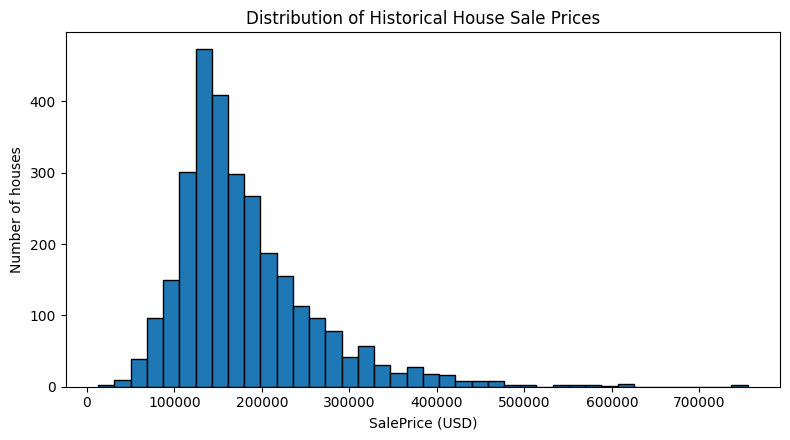

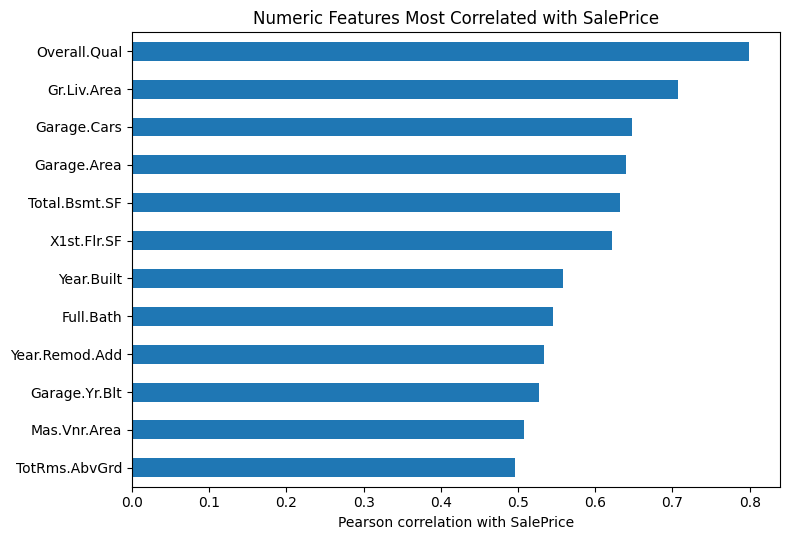

Interpretation:
- A right-skewed price distribution means some homes are much more expensive than typical homes.
- Correlation describes numeric linear association; it does not prove causation and does not capture every categorical or nonlinear relationship.
- Missingness is common in some optional features. The imputation pipeline handles it without deleting most rows.
- Potential outliers should be reviewed with domain context instead of removed automatically.


In [5]:
# Descriptive statistics for the sale-price target.
display(y.describe().to_frame(name="SalePrice (USD)"))

# Chart 1: target distribution.
plt.figure(figsize=(8, 4.5))
plt.hist(y, bins=40, edgecolor="black")
plt.title("Distribution of Historical House Sale Prices")
plt.xlabel("SalePrice (USD)")
plt.ylabel("Number of houses")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "saleprice_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

# Chart 2: strongest correlations among numeric columns and SalePrice.
numeric_with_target = df.select_dtypes(include=np.number)
correlations = numeric_with_target.corr(numeric_only=True)[TARGET].drop(TARGET).dropna()
top_corr = correlations.reindex(correlations.abs().sort_values(ascending=False).head(12).index).sort_values()
plt.figure(figsize=(8, 5.5))
top_corr.plot(kind="barh")
plt.title("Numeric Features Most Correlated with SalePrice")
plt.xlabel("Pearson correlation with SalePrice")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "top_numeric_correlations.png", dpi=150, bbox_inches="tight")
plt.show()

print("Interpretation:")
print("- A right-skewed price distribution means some homes are much more expensive than typical homes.")
print("- Correlation describes numeric linear association; it does not prove causation and does not capture every categorical or nonlinear relationship.")
print("- Missingness is common in some optional features. The imputation pipeline handles it without deleting most rows.")
print("- Potential outliers should be reviewed with domain context instead of removed automatically.")

### Build reusable preprocessing and evaluation functions

A single scikit-learn `Pipeline` keeps imputing, encoding, scaling, and modeling together. This reduces the risk that training and prediction use different preprocessing rules.

In [6]:
def make_preprocessor():
    """Create preprocessing steps; fit values are learned from training rows only."""
    numeric_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=2)),
    ])
    return ColumnTransformer(
        transformers=[
            ("numeric", numeric_transformer, numeric_columns),
            ("categorical", categorical_transformer, categorical_columns),
        ],
        remainder="drop",
    )


def regression_metrics(y_true, y_pred):
    """Calculate common regression metrics. Lower RMSE/MAE and higher R² are preferred."""
    return {
        "RMSE (USD)": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAE (USD)": float(mean_absolute_error(y_true, y_pred)),
        "R2": float(r2_score(y_true, y_pred)),
    }

print("Preprocessing function ready.")

Preprocessing function ready.


# Task 5 — Build the baseline model

We fit Linear Regression first. This baseline gives us a reference point: the alternative models should be judged by measured validation performance, not by the assumption that a more complex model must be better.

In [7]:
baseline_pipeline = Pipeline(steps=[
    ("preprocessor", make_preprocessor()),
    ("model", LinearRegression()),
])

start_time = time.time()
baseline_pipeline.fit(X_train, y_train)
baseline_val_predictions = baseline_pipeline.predict(X_val)
baseline_metrics = regression_metrics(y_val, baseline_val_predictions)
baseline_seconds = time.time() - start_time

print("Linear Regression baseline validation metrics:")
for metric_name, metric_value in baseline_metrics.items():
    print(f"{metric_name}: {metric_value:,.4f}")
print(f"Fit time: {baseline_seconds:.2f} seconds")

Linear Regression baseline validation metrics:
RMSE (USD): 20,862.5845
MAE (USD): 15,485.9399
R2: 0.9200
Fit time: 0.19 seconds


# Task 6 — Improve and compare models

We test Random Forest and Gradient Boosting with practical starting settings. The validation set is used to compare all three candidates. This notebook keeps the tuning process understandable rather than running a very large grid search; more extensive cross-validation and hyperparameter tuning are reasonable future improvements.

In [8]:
model_candidates = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=150,
        min_samples_leaf=2,
        max_features=0.8,
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=2,
        loss="squared_error",
        random_state=RANDOM_STATE,
    ),
}

validation_records = []
validation_pipelines = {}
for model_name, estimator in model_candidates.items():
    candidate_pipeline = Pipeline(steps=[
        ("preprocessor", make_preprocessor()),
        ("model", clone(estimator)),
    ])
    started = time.time()
    candidate_pipeline.fit(X_train, y_train)
    val_predictions = candidate_pipeline.predict(X_val)
    measured = regression_metrics(y_val, val_predictions)
    validation_records.append({
        "Model": model_name,
        **measured,
        "Fit seconds": round(time.time() - started, 2),
    })
    validation_pipelines[model_name] = candidate_pipeline

validation_results = pd.DataFrame(validation_records).sort_values("RMSE (USD)").reset_index(drop=True)
display(validation_results.style.format({
    "RMSE (USD)": "${:,.2f}",
    "MAE (USD)": "${:,.2f}",
    "R2": "{:.4f}",
    "Fit seconds": "{:.2f}",
}))

best_model_name = str(validation_results.loc[0, "Model"])
print("Selected using the lowest validation RMSE:", best_model_name)
print("Why: RMSE places greater weight on larger absolute prediction errors.")
print("The validation results, rather than the final test set, determine model selection.")
validation_results.to_csv(OUTPUT_DIR / "validation_model_comparison.csv", index=False)

,Model,RMSE (USD),MAE (USD),R2,Fit seconds
0,Random Forest,"$20,124.77","$14,347.72",0.9255,8.32
1,Linear Regression,"$20,862.58","$15,485.94",0.9200,0.20
2,Gradient Boosting,"$20,971.00","$15,241.81",0.9192,1.19


Selected using the lowest validation RMSE: Random Forest
Why: RMSE places greater weight on larger absolute prediction errors.
The validation results, rather than the final test set, determine model selection.


# Task 7 — Evaluate the selected model

After selecting a candidate from validation results, we refit that model on the entire 80% training pool and evaluate it once on the held-out 20% test set. This test score is the final estimate of performance on records not used during model fitting or model selection.

In [9]:
selected_estimator = clone(model_candidates[best_model_name])
final_pipeline = Pipeline(steps=[
    ("preprocessor", make_preprocessor()),
    ("model", selected_estimator),
])

started = time.time()
final_pipeline.fit(X_train_full, y_train_full)
final_fit_seconds = time.time() - started

test_predictions = final_pipeline.predict(X_test)
final_test_metrics = regression_metrics(y_test, test_predictions)
print("Final held-out test metrics for", best_model_name)
for metric_name, metric_value in final_test_metrics.items():
    if metric_name == "R2":
        print(f"{metric_name}: {metric_value:.4f}")
    else:
        print(f"{metric_name}: ${metric_value:,.2f}")
print(f"Final fit time: {final_fit_seconds:.2f} seconds")
print(f"Held-out test rows: {len(X_test):,}")

# Store a sample of predictions so errors can be reviewed.
prediction_review = pd.DataFrame({
    "Actual SalePrice (USD)": y_test.to_numpy(),
    "Predicted SalePrice (USD)": test_predictions,
})
prediction_review["Error (USD)"] = (
    prediction_review["Predicted SalePrice (USD)"] - prediction_review["Actual SalePrice (USD)"]
)
prediction_review["Absolute Error (USD)"] = prediction_review["Error (USD)"].abs()
display(prediction_review.head(10).style.format("${:,.2f}"))
prediction_review.to_csv(OUTPUT_DIR / "test_set_predictions.csv", index=False)

# The RMSE, MAE, and R2 values have distinct meanings.
print("\nMetric interpretation:")
print("- RMSE: typical scale of error with a stronger penalty for large errors.")
print("- MAE: average absolute difference between predictions and actual prices.")
print("- R2: proportion of variation in test prices explained by the predictions relative to a mean-only reference.")
print("These are split-specific estimates; they are not a guarantee for future transactions or other locations.")

Final held-out test metrics for Random Forest
RMSE (USD): $26,285.70
MAE (USD): $15,516.53
R2: 0.9138
Final fit time: 11.37 seconds
Held-out test rows: 586


,Actual SalePrice (USD),Predicted SalePrice (USD),Error (USD),Absolute Error (USD)
0,"$161,000.00","$182,363.73","$21,363.73","$21,363.73"
1,"$116,000.00","$103,265.09","$-12,734.91","$12,734.91"
2,"$196,500.00","$193,342.21","$-3,157.79","$3,157.79"
3,"$123,600.00","$116,929.33","$-6,670.67","$6,670.67"
4,"$126,000.00","$112,905.06","$-13,094.94","$13,094.94"
5,"$174,190.00","$176,066.47","$1,876.47","$1,876.47"
6,"$200,000.00","$165,191.60","$-34,808.40","$34,808.40"
7,"$148,500.00","$148,602.69",$102.69,$102.69
8,"$88,750.00","$89,818.66","$1,068.66","$1,068.66"
9,"$409,900.00","$356,234.68","$-53,665.32","$53,665.32"



Metric interpretation:
- RMSE: typical scale of error with a stronger penalty for large errors.
- MAE: average absolute difference between predictions and actual prices.
- R2: proportion of variation in test prices explained by the predictions relative to a mean-only reference.
These are split-specific estimates; they are not a guarantee for future transactions or other locations.


### Error analysis

We inspect actual-versus-predicted values and residuals (prediction minus actual). Large residuals may indicate uncommon property combinations, high-priced homes, data issues, or patterns not captured by the model.

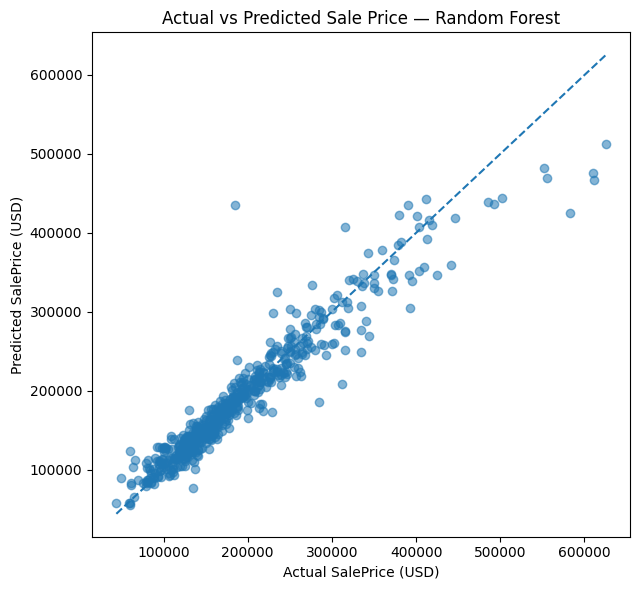

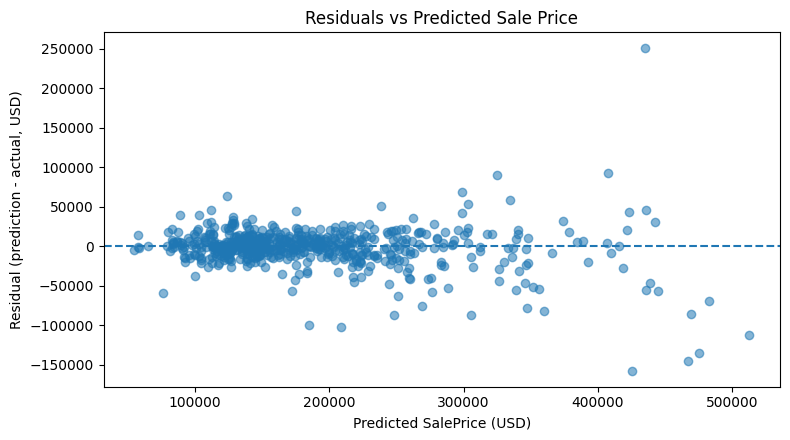

Mean residual (USD): -1658.09
Median absolute error (USD): 9804.21
90th percentile absolute error (USD): 32990.35
Largest absolute error (USD): 250257.61
Review the largest errors, compare lower- and higher-priced houses, and check neighborhood patterns before real-world use.


In [10]:
# Actual vs predicted chart.
plt.figure(figsize=(6.5, 6))
plt.scatter(y_test, test_predictions, alpha=0.55)
minimum = min(float(y_test.min()), float(np.min(test_predictions)))
maximum = max(float(y_test.max()), float(np.max(test_predictions)))
plt.plot([minimum, maximum], [minimum, maximum], linestyle="--")
plt.title(f"Actual vs Predicted Sale Price — {best_model_name}")
plt.xlabel("Actual SalePrice (USD)")
plt.ylabel("Predicted SalePrice (USD)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "actual_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()

# Residual plot.
residuals = test_predictions - y_test.to_numpy()
plt.figure(figsize=(8, 4.5))
plt.scatter(test_predictions, residuals, alpha=0.55)
plt.axhline(0, linestyle="--")
plt.title("Residuals vs Predicted Sale Price")
plt.xlabel("Predicted SalePrice (USD)")
plt.ylabel("Residual (prediction - actual, USD)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "residuals_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()

print("Mean residual (USD):", round(float(np.mean(residuals)), 2))
print("Median absolute error (USD):", round(float(np.median(np.abs(residuals))), 2))
print("90th percentile absolute error (USD):", round(float(np.percentile(np.abs(residuals), 90)), 2))
print("Largest absolute error (USD):", round(float(np.max(np.abs(residuals))), 2))
print("Review the largest errors, compare lower- and higher-priced houses, and check neighborhood patterns before real-world use.")

### Inspect feature importance (where supported)

For tree models, feature importance can help summarize which encoded features contributed most to model splits. Importance is not the same as causation, and one-hot encoded categories appear as separate features.

,Encoded feature,Importance
3,numeric__Overall.Qual,0.509000
15,numeric__Gr.Liv.Area,0.099207
25,numeric__Garage.Cars,0.071734
12,numeric__X1st.Flr.SF,0.036685
5,numeric__Year.Built,0.029278
11,numeric__Total.Bsmt.SF,0.027354
8,numeric__BsmtFin.SF.1,0.022032
13,numeric__X2nd.Flr.SF,0.021209
18,numeric__Full.Bath,0.017024
26,numeric__Garage.Area,0.016834


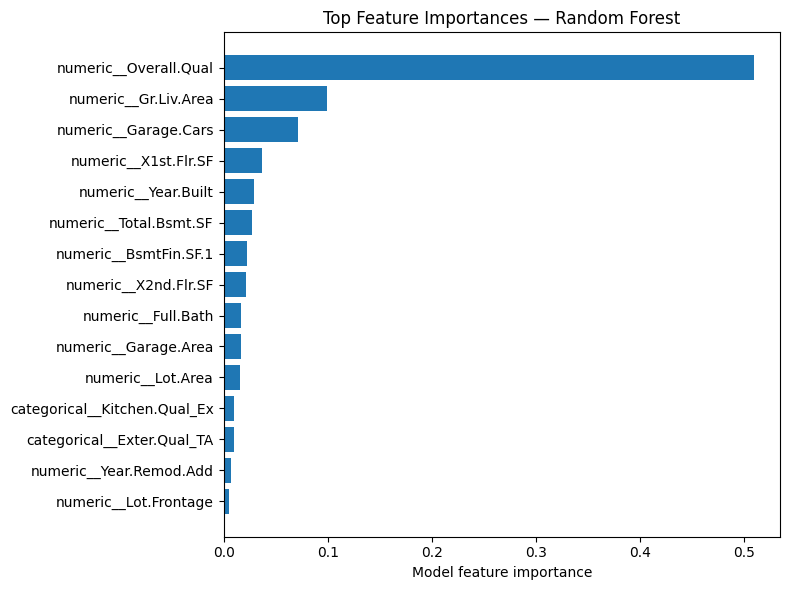

In [11]:
fitted_model = final_pipeline.named_steps["model"]
try:
    transformed_feature_names = final_pipeline.named_steps["preprocessor"].get_feature_names_out()
except Exception as exc:
    transformed_feature_names = None
    print("Could not retrieve transformed feature names:", exc)

if hasattr(fitted_model, "feature_importances_") and transformed_feature_names is not None:
    importances = np.asarray(fitted_model.feature_importances_)
    top_importance = pd.DataFrame({
        "Encoded feature": transformed_feature_names,
        "Importance": importances,
    }).sort_values("Importance", ascending=False).head(15).sort_values("Importance")
    display(top_importance.sort_values("Importance", ascending=False))
    plt.figure(figsize=(8, 6))
    plt.barh(top_importance["Encoded feature"], top_importance["Importance"])
    plt.title(f"Top Feature Importances — {best_model_name}")
    plt.xlabel("Model feature importance")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "top_feature_importances.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("The selected estimator does not expose tree feature_importances_.")
    print("For a linear model, use carefully interpreted coefficients or permutation importance instead.")

# Task 8 — Test the complete solution

The function below represents the input-to-output prototype. A user supplies a dictionary of property details. The function checks for unknown field names and rejects negative values for selected non-negative measurements, fills omitted fields as missing, and passes the row through the same saved preprocessing and model pipeline used during training.

For a realistic interface, collect the most relevant fields and explain which values are optional. The model can technically fill missing fields, but more complete and accurate information may improve the usefulness of the estimate.

In [12]:
NON_NEGATIVE_FEATURES = [
    "Lot.Frontage", "Lot.Area", "Mas.Vnr.Area", "BsmtFin.SF.1", "BsmtFin.SF.2",
    "Bsmt.Unf.SF", "Total.Bsmt.SF", "X1st.Flr.SF", "X2nd.Flr.SF", "Low.Qual.Fin.SF",
    "Gr.Liv.Area", "Bsmt.Full.Bath", "Bsmt.Half.Bath", "Full.Bath", "Half.Bath",
    "Bedroom.AbvGr", "Kitchen.AbvGr", "TotRms.AbvGrd", "Fireplaces", "Garage.Cars",
    "Garage.Area", "Wood.Deck.SF", "Open.Porch.SF", "Enclosed.Porch", "X3Ssn.Porch",
    "Screen.Porch", "Pool.Area", "Misc.Val",
]
NON_NEGATIVE_FEATURES = [c for c in NON_NEGATIVE_FEATURES if c in feature_columns]
YEAR_FEATURES = [c for c in ["Year.Built", "Year.Remod.Add", "Garage.Yr.Blt"] if c in feature_columns]


def predict_house_price(property_details):
    """Predict a house price from a dict of original CSV feature names.

    Example keys: Neighborhood, Gr.Liv.Area, Overall.Qual, Year.Built, Garage.Cars.
    Unspecified features are treated as missing and imputed by the trained pipeline.
    """
    if not isinstance(property_details, dict):
        raise TypeError("property_details must be a dictionary of feature names and values.")
    unknown = set(property_details) - set(feature_columns)
    if unknown:
        raise ValueError(f"Unknown feature name(s): {sorted(unknown)}")

    for col in NON_NEGATIVE_FEATURES:
        value = property_details.get(col)
        if value is not None and not pd.isna(value) and float(value) < 0:
            raise ValueError(f"{col} cannot be negative.")
    for col in YEAR_FEATURES:
        value = property_details.get(col)
        if value is not None and not pd.isna(value) and not (1800 <= float(value) <= 2100):
            raise ValueError(f"{col} must be between 1800 and 2100 when supplied.")

    row = {col: np.nan for col in feature_columns}
    row.update({k: v for k, v in property_details.items() if v is not None})
    input_frame = pd.DataFrame([row], columns=feature_columns)
    predicted_price = float(final_pipeline.predict(input_frame)[0])
    if not np.isfinite(predicted_price):
        raise ValueError("The model did not return a finite price prediction.")
    return predicted_price

print("Prototype prediction function created.")

Prototype prediction function created.


### Test cases

These tests cover a complete row from the held-out test set, a partial but realistic home description, an unseen neighborhood category, and an invalid negative lot size.

In [13]:
test_case_results = []

# Test 1: use one actual held-out row (end-to-end schema and preprocessing check).
realistic_complete_case = X_test.iloc[0].to_dict()
complete_prediction = predict_house_price(realistic_complete_case)
test_case_results.append({
    "Test case": "Complete held-out property",
    "Outcome": "PASS" if np.isfinite(complete_prediction) and complete_prediction > 0 else "FAIL",
    "Predicted price (USD)": complete_prediction,
})

# Test 2: only a subset of common fields; other features are imputed.
partial_case = {
    "Neighborhood": "NAmes",
    "Gr.Liv.Area": 1500,
    "Overall.Qual": 6,
    "Year.Built": 1990,
    "Bedroom.AbvGr": 3,
    "Full.Bath": 2,
    "Garage.Cars": 2,
    "Total.Bsmt.SF": 900,
    "Lot.Area": 8000,
}
partial_prediction = predict_house_price(partial_case)
test_case_results.append({
    "Test case": "Partial property details",
    "Outcome": "PASS" if np.isfinite(partial_prediction) and partial_prediction > 0 else "FAIL",
    "Predicted price (USD)": partial_prediction,
})

# Test 3: unseen categorical label; OneHotEncoder(handle_unknown='ignore') should handle it.
unseen_case = dict(partial_case)
unseen_case["Neighborhood"] = "Neighborhood_Not_In_Training_Data"
unseen_prediction = predict_house_price(unseen_case)
test_case_results.append({
    "Test case": "Unseen neighborhood category",
    "Outcome": "PASS" if np.isfinite(unseen_prediction) and unseen_prediction > 0 else "FAIL",
    "Predicted price (USD)": unseen_prediction,
})

# Test 4: reject an invalid negative lot area.
try:
    predict_house_price({"Lot.Area": -500})
    invalid_rejected = False
except ValueError:
    invalid_rejected = True
assert invalid_rejected, "Negative Lot.Area should be rejected."
test_case_results.append({
    "Test case": "Negative lot area rejected",
    "Outcome": "PASS" if invalid_rejected else "FAIL",
    "Predicted price (USD)": np.nan,
})

test_results = pd.DataFrame(test_case_results)
display(test_results.style.format({"Predicted price (USD)": "${:,.2f}"}))
assert (test_results["Outcome"] == "PASS").all(), "At least one workflow test failed."
test_results.to_csv(OUTPUT_DIR / "workflow_test_results.csv", index=False)
print("All workflow checks passed.")

,Test case,Outcome,Predicted price (USD)
0,Complete held-out property,PASS,"$182,363.73"
1,Partial property details,PASS,"$171,625.44"
2,Unseen neighborhood category,PASS,"$171,847.10"
3,Negative lot area rejected,PASS,$nan


All workflow checks passed.


### Optional interactive web-style demo in Colab

The tests above already demonstrate the complete input-to-output workflow. To open a simple Gradio form as a web-style prototype in Colab, change `ENABLE_GRADIO_DEMO` to `True` and run this cell. The demo uses a small subset of fields; fields not shown in the form are imputed by the model. A temporary share link may be created by Gradio when running in Colab, so only use non-sensitive demonstration inputs.

In [14]:
ENABLE_GRADIO_DEMO = False  # Change to True to launch the optional UI in Colab.

if ENABLE_GRADIO_DEMO:
    try:
        import gradio as gr
        def gradio_predict(neighborhood, living_area, lot_area, quality, year_built, bedrooms, bathrooms, garage_cars):
            details = {
                "Neighborhood": neighborhood,
                "Gr.Liv.Area": living_area,
                "Lot.Area": lot_area,
                "Overall.Qual": quality,
                "Year.Built": year_built,
                "Bedroom.AbvGr": bedrooms,
                "Full.Bath": bathrooms,
                "Garage.Cars": garage_cars,
            }
            estimate = predict_house_price(details)
            return f"Estimated sale price: ${estimate:,.0f} USD\n\nThis is a machine-learning estimate, not a guaranteed sale price or professional appraisal."

        neighborhood_choices = sorted(df["Neighborhood"].dropna().astype(str).unique().tolist()) if "Neighborhood" in df.columns else ["Unknown"]
        with gr.Blocks() as demo:
            gr.Markdown("# Ames House Sale Price Estimate")
            gr.Markdown("Educational prototype. Prices are in USD, based on historical Ames, Iowa sales.")
            neighborhood = gr.Dropdown(neighborhood_choices, value=neighborhood_choices[0], label="Neighborhood")
            living_area = gr.Number(value=1500, label="Above-ground living area (sq ft)")
            lot_area = gr.Number(value=8000, label="Lot area (sq ft)")
            quality = gr.Slider(1, 10, value=6, step=1, label="Overall quality (1-10)")
            year_built = gr.Number(value=1990, label="Year built")
            bedrooms = gr.Number(value=3, label="Bedrooms above ground")
            bathrooms = gr.Number(value=2, label="Full bathrooms")
            garage_cars = gr.Number(value=2, label="Garage capacity (cars)")
            submit = gr.Button("Predict Sale Price")
            output = gr.Textbox(label="Prediction")
            submit.click(
                fn=gradio_predict,
                inputs=[neighborhood, living_area, lot_area, quality, year_built, bedrooms, bathrooms, garage_cars],
                outputs=output,
            )
        demo.launch(share=True)
    except ImportError:
        print("Gradio is not installed. In Colab, run %pip install gradio, then rerun this cell.")
else:
    print("Optional Gradio demo is disabled. Set ENABLE_GRADIO_DEMO = True to launch it in Colab.")

Optional Gradio demo is disabled. Set ENABLE_GRADIO_DEMO = True to launch it in Colab.


## Save the trained model and key results

The serialized bundle contains the whole preprocessing-plus-model pipeline, the feature order, selected model name, final test metrics, and the scikit-learn version. Saving the entire pipeline ensures new inputs use the same imputing and encoding steps as training.

In [15]:
model_bundle = {
    "pipeline": final_pipeline,
    "target_column": TARGET,
    "feature_columns": feature_columns,
    "identifier_columns_excluded": identifier_columns,
    "selected_model": best_model_name,
    "validation_results": validation_results.to_dict(orient="records"),
    "final_test_metrics": final_test_metrics,
    "price_currency": "USD",
    "random_state": RANDOM_STATE,
    "sklearn_version": sklearn.__version__,
}
model_path = Path("ames_housing_model.joblib")
joblib.dump(model_bundle, model_path)

with open(OUTPUT_DIR / "final_test_metrics.json", "w", encoding="utf-8") as f:
    json.dump(final_test_metrics, f, indent=2)
with open(OUTPUT_DIR / "project_run_summary.json", "w", encoding="utf-8") as f:
    json.dump({
        "dataset_rows": int(df.shape[0]),
        "dataset_columns": int(df.shape[1]),
        "predictor_count": int(len(feature_columns)),
        "training_rows": int(len(X_train_full)),
        "test_rows": int(len(X_test)),
        "validation_results": validation_results.to_dict(orient="records"),
        "best_model": best_model_name,
        "final_test_metrics": final_test_metrics,
    }, f, indent=2)

print("Saved trained model to:", model_path.resolve())
print("Supporting outputs saved in:", OUTPUT_DIR.resolve())
print("Files:")
for item in sorted(OUTPUT_DIR.iterdir()):
    print(" -", item.name)

Saved trained model to: /mnt/data/ames_housing_colab_project/ames_housing_model.joblib
Supporting outputs saved in: /mnt/data/ames_housing_colab_project/project_outputs
Files:
 - actual_vs_predicted.png
 - final_test_metrics.json
 - project_run_summary.json
 - residuals_vs_predicted.png
 - saleprice_distribution.png
 - test_set_predictions.csv
 - top_feature_importances.png
 - top_numeric_correlations.png
 - validation_model_comparison.csv
 - workflow_test_results.csv


## Conclusions, limitations, and next steps

### What this notebook demonstrates

- A clear supervised-regression problem and target.
- Data-quality review, feature preprocessing, exploratory charts, and a baseline.
- Validation-based comparison of Linear Regression, Random Forest, and Gradient Boosting.
- Final held-out evaluation with RMSE, MAE, and R².
- Residual inspection, saved model pipeline, and tested input-to-output predictions.

### Limitations

1. **Geographic limitation:** the dataset describes historical properties in Ames, Iowa; results do not automatically generalize to Ethiopia or another market.
2. **Time limitation:** recorded sale years are historical; present-day prices and market conditions may differ.
3. **Prediction uncertainty:** an estimate may be wrong, especially for unusual homes or high-value outliers.
4. **Feature limitations:** missing values are imputed, and the model only knows features available in this dataset.
5. **Evaluation limitation:** one fixed validation/test split is useful for a prototype but does not replace repeated cross-validation and external validation.
6. **Fairness and responsible use:** examine errors for relevant property groups and explain uncertainty before real-world use.

### Future improvements

Try repeated cross-validation and a small hyperparameter search; compare predictions by price band and neighborhood; add prediction intervals and feature explanations; validate against a more recent and locally representative dataset; and deploy through a secured web app/API only after further validation.

### References

- Group 23, *Real Estate House Sale Price Prediction Using Machine Learning*, YEEAP Module 4 proposal, submitted September 30, 2026 (uploaded project proposal PDF).
- Kaggle, *House Prices: Advanced Regression Techniques*: https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques
- CMU Statistics & Data Science Data Repository, *House prices in Ames, Iowa*: https://cmustatistics.github.io/data-repository/money/ames-housing.html (dataset overview and sale-price units).
- Scikit-learn documentation: https://scikit-learn.org/stable/
